<a href="https://colab.research.google.com/github/esneydersandoval31-alt/608142-DEEP-LEARNING--CONCEPTOS/blob/main/R2_A1_S10_Redes_Neuronales_V.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from torchvision.models import ResNet18_Weights

class EmbeddingNet(nn.Module):
    def __init__(self):
        super(EmbeddingNet, self).__init__()
        # Usamos un modelo base preentrenado con la API recomendada actualmente
        resnet = models.resnet18(weights=ResNet18_Weights.DEFAULT)
        # Eliminamos la capa final de clasificación para obtener embeddings de 128 dimensiones
        self.base_model = nn.Sequential(*list(resnet.children())[:-1])
        self.fc = nn.Linear(512, 128)

    def forward(self, x):
        x = self.base_model(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        # Normalizamos el embedding para métricas de distancia coseno/euclidiana
        x = F.normalize(x, p=2, dim=1)
        return x

class SiameseNetwork(nn.Module):
    def __init__(self):
        super(SiameseNetwork, self).__init__()
        self.embedding_net = EmbeddingNet()

    def forward(self, input1, input2):
        output1 = self.embedding_net(input1)
        output2 = self.embedding_net(input2)
        return output1, output2

class TripletLoss(nn.Module):
    def __init__(self, margin=0.2):
        super(TripletLoss, self).__init__()
        self.margin = margin

    def forward(self, anchor, positive, negative):
        distance_positive = (anchor - positive).pow(2).sum(1)
        distance_negative = (anchor - negative).pow(2).sum(1)
        loss = F.relu(distance_positive - distance_negative + self.margin)
        return loss.mean()

In [ ]:
import torch
import torch.optim as optim

# 1. Inicializar el modelo, la función de pérdida y el optimizador
# Para Triplet Loss, usaremos directamente la red de embeddings (EmbeddingNet)
model = EmbeddingNet()
criterion = TripletLoss(margin=0.2)
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Poner el modelo en modo de entrenamiento
model.train()

# 2. Simular un lote (batch) de datos: ancla, positivo y negativo
# En un caso real, estos vendrían de tu DataLoader estructurado para tripletas
batch_size = 4
# Simulamos imágenes de 3 canales y 224x224 píxeles (tamaño estándar para ResNet)
anchors = torch.randn(batch_size, 3, 224, 224)
positives = torch.randn(batch_size, 3, 224, 224)
negatives = torch.randn(batch_size, 3, 224, 224)

# 3. Limpiar los gradientes acumulados del optimizador
optimizer.zero_grad()

# 4. Pasar cada elemento de la tripleta por la red para obtener los embeddings
anchor_embeddings = model(anchors)
positive_embeddings = model(positives)
negative_embeddings = model(negatives)

# 5. Calcular la pérdida usando la clase TripletLoss definida previamente
loss = criterion(anchor_embeddings, positive_embeddings, negative_embeddings)

# 6. Realizar el paso de Backpropagation
loss.backward()

# 7. Actualizar los parámetros de la red
optimizer.step()

print(f"Paso de entrenamiento completado exitosamente.")
print(f"Pérdida obtenida en este lote: {loss.item():.4f}")

Paso de entrenamiento completado exitosamente.
Pérdida obtenida en este lote: 0.2481


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
import torch

def visualize_embeddings_tsne(embeddings, labels, perplexity=30, max_iter=1000):
    """
    Reduce la dimensionalidad de los embeddings a 2D usando t-SNE y los grafica.

    Parámetros:
    - embeddings (Tensor o ndarray): Embeddings generados por la red de tamaño (N, D).
    - labels (Tensor, list o ndarray): Etiquetas numéricas o de texto correspondientes a cada embedding.
    - perplexity (int): Parámetro de t-SNE que se relaciona con el número de vecinos más cercanos.
    - max_iter (int): Número de iteraciones máximas para la optimización de t-SNE.
    """
    # Convertir a numpy si es un tensor de PyTorch
    if isinstance(embeddings, torch.Tensor):
        embeddings = embeddings.detach().cpu().numpy()
    if isinstance(labels, torch.Tensor):
        labels = labels.detach().cpu().numpy()
    else:
        labels = np.array(labels)

    print("Calculando reducción dimensional con t-SNE...")
    # Configurar y aplicar t-SNE utilizando max_iter en lugar de n_iter
    tsne = TSNE(n_components=2, perplexity=perplexity, max_iter=max_iter, random_state=42)
    embeddings_2d = tsne.fit_transform(embeddings)

    # Crear la visualización
    plt.figure(figsize=(10, 8))
    sns.scatterplot(
        x=embeddings_2d[:, 0],
        y=embeddings_2d[:, 1],
        hue=labels,
        palette='viridis',
        style=labels,
        s=100,
        alpha=0.8
    )

    plt.title('Visualización de Embeddings mediante t-SNE')
    plt.xlabel('Dimensión 1 de t-SNE')
    plt.ylabel('Dimensión 2 de t-SNE')
    plt.legend(title='Clases', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

Calculando reducción dimensional con t-SNE...


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


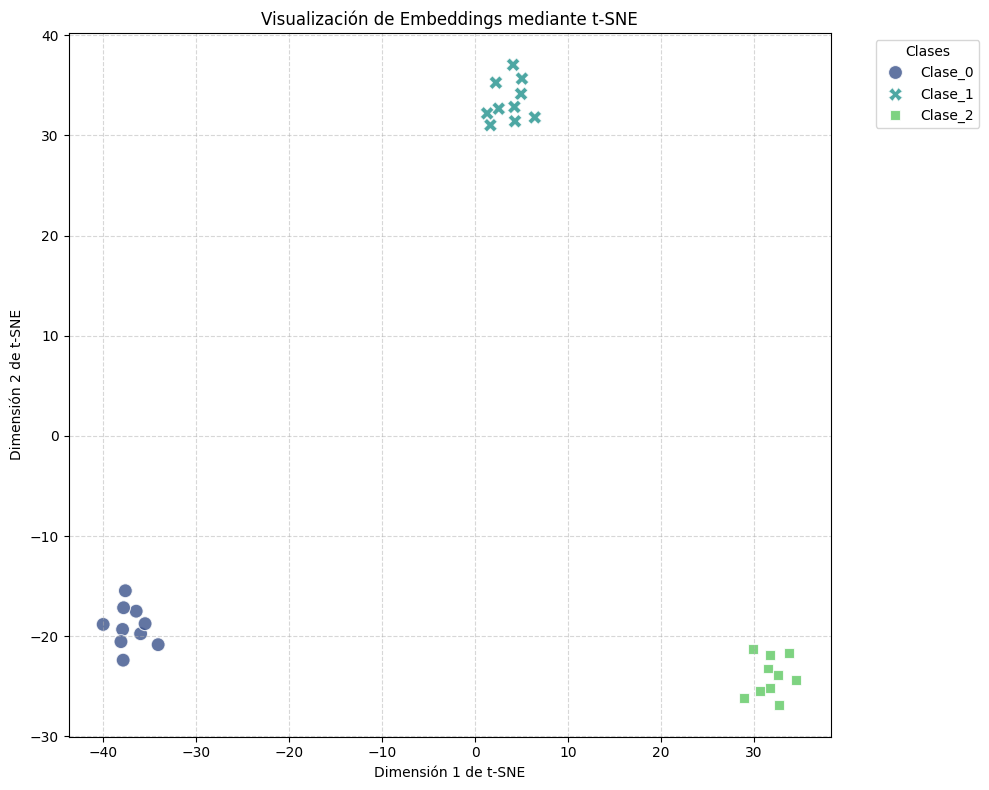

In [ ]:
# Ejemplo de uso con datos simulados
# Generamos 30 embeddings simulados para 3 clases distintas (10 muestras por clase)
simulated_embeddings = []
simulated_labels = []

# Simulamos clusters para que t-SNE muestre una agrupación lógica
for class_idx in range(3):
    # Añadimos ruido específico a cada clase sobre el embedding base
    base_vector = np.random.randn(128) * 5
    for _ in range(10):
        noise = np.random.randn(128) * 0.5
        simulated_embeddings.append(base_vector + noise)
        simulated_labels.append(f"Clase_{class_idx}")

simulated_embeddings = np.array(simulated_embeddings)

# Ejecutar la visualización
visualize_embeddings_tsne(simulated_embeddings, simulated_labels, perplexity=5)

In [ ]:
from torch.utils.data import Dataset, DataLoader

# 1. Definición de un Dataset sintético para generar tripletas de imágenes
class SyntheticTripletDataset(Dataset):
    def __init__(self, num_samples=100):
        self.num_samples = num_samples

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        # Cada muestra es una tripleta: (anchor, positive, negative)
        anchor = torch.randn(3, 224, 224)
        positive = torch.randn(3, 224, 224)
        negative = torch.randn(3, 224, 224)
        return anchor, positive, negative

# 2. Configurar el Dataset y DataLoader
dataset = SyntheticTripletDataset(num_samples=40)  # 40 tripletas en total
train_loader = DataLoader(dataset, batch_size=8, shuffle=True)

# 3. Inicializar modelo, pérdida y optimizador
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = EmbeddingNet().to(device)
criterion = TripletLoss(margin=0.2)
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 4. Bucle de entrenamiento por épocas
epochs = 5
print(f"Iniciando entrenamiento en: {device}\n")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for batch_idx, (anchors, positives, negatives) in enumerate(train_loader):
        # Mover datos al dispositivo (GPU/CPU)
        anchors = anchors.to(device)
        positives = positives.to(device)
        negatives = negatives.to(device)

        # Limpiar gradientes
        optimizer.zero_grad()

        # Forward pass
        anchor_embed = model(anchors)
        positive_embed = model(positives)
        negative_embed = model(negatives)

        # Calcular pérdida
        loss = criterion(anchor_embed, positive_embed, negative_embed)

        # Backward pass y optimización
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    # Calcular pérdida promedio de la época
    epoch_loss = running_loss / len(train_loader)
    print(f"Época [{epoch+1}/{epochs}] - Pérdida Promedio: {epoch_loss:.4f}")

print("\n¡Entrenamiento finalizado con éxito!")

Iniciando entrenamiento en: cpu

Época [1/5] - Pérdida Promedio: 0.2146
Época [2/5] - Pérdida Promedio: 0.2324
Época [3/5] - Pérdida Promedio: 0.1868
Época [4/5] - Pérdida Promedio: 0.2412
Época [5/5] - Pérdida Promedio: 0.2042

¡Entrenamiento finalizado con éxito!


### Carga de un Dataset de Imágenes Propio para Tripletas

Este código define un dataset personalizado que toma un directorio estructurado por clases, indexa las imágenes usando `ImageFolder`, y genera dinámicamente tripletas en cada iteración asegurando que el **Anchor** y el **Positive** pertenezcan a la misma clase, y el **Negative** a una clase diferente.

In [ ]:
import os
import random
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder

class RealTripletImageDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        """
        Args:
            root_dir (string): Ruta al directorio principal con las carpetas de clases.
            transform (callable, optional): Transformaciones a aplicar a las imágenes.
        """
        self.image_folder = ImageFolder(root=root_dir)
        self.transform = transform

        # Agrupamos los índices de las imágenes por clase para facilitar la selección
        self.class_to_indices = {}
        for idx, (_, class_idx) in enumerate(self.image_folder.samples):
            if class_idx not in self.class_to_indices:
                self.class_to_indices[class_idx] = []
            self.class_to_indices[class_idx].append(idx)

        self.classes = list(self.class_to_indices.keys())

    def __len__(self):
        return len(self.image_folder)

    def __getitem__(self, idx):
        # 1. Obtener la imagen de Ancla (Anchor) y su clase correspondiente
        anchor_path, anchor_class = self.image_folder.samples[idx]
        anchor_img = Image.open(anchor_path).convert('RGB')

        # 2. Seleccionar un Positivo (misma clase, distinto índice si es posible)
        pos_indices = self.class_to_indices[anchor_class]
        if len(pos_indices) > 1:
            pos_idx = random.choice([i for i in pos_indices if i != idx])
        else:
            pos_idx = idx  # Si solo hay una imagen en la clase
        pos_path, _ = self.image_folder.samples[pos_idx]
        positive_img = Image.open(pos_path).convert('RGB')

        # 3. Seleccionar un Negativo (clase distinta)
        neg_class = random.choice([c for c in self.classes if c != anchor_class])
        neg_idx = random.choice(self.class_to_indices[neg_class])
        neg_path, _ = self.image_folder.samples[neg_idx]
        negative_img = Image.open(neg_path).convert('RGB')

        # Aplicar transformaciones
        if self.transform:
            anchor_img = self.transform(anchor_img)
            positive_img = self.transform(positive_img)
            negative_img = self.transform(negative_img)

        return anchor_img, positive_img, negative_img

# --- Configuración de Transformaciones Estándar para ResNet ---
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# --- Ejemplo de Uso (Reemplaza 'ruta/a/tu/dataset' con tu directorio real) ---
# dataset_camino = 'ruta/a/tu/dataset'
# if os.path.exists(dataset_camino):
#     my_dataset = RealTripletImageDataset(root_dir=dataset_camino, transform=data_transforms)
#     my_loader = DataLoader(my_dataset, batch_size=8, shuffle=True)
#     print(f"Cargadas {len(my_dataset)} imágenes de {len(my_dataset.classes)} clases distintas.")

### Simulación y Entrenamiento con un Dataset Real en Disco

Creamos una estructura de carpetas de prueba con imágenes simuladas para verificar que el cargador de datos `RealTripletImageDataset` y el bucle de entrenamiento funcionan de extremo a extremo sin problemas de integración.

In [ ]:
import os
from PIL import Image
import numpy as np
import torch
import torch.optim as optim
from torch.utils.data import DataLoader

# --- 1. Crear un Dataset de imágenes temporal en disco ---
base_dir = "/content/mi_dataset_simulado"
os.makedirs(base_dir, exist_ok=True)
clases = ["perros", "gatos", "pajaros"]

print("Generando imágenes de prueba en disco...")
for clase in clases:
    clase_path = os.path.join(base_dir, clase)
    os.makedirs(clase_path, exist_ok=True)
    for i in range(10):  # 10 imágenes por clase
        # Crear una imagen RGB aleatoria de 224x224 píxeles
        img_data = (np.random.rand(224, 224, 3) * 255).astype(np.uint8)
        img = Image.fromarray(img_data)
        img.save(os.path.join(clase_path, f"img_{i}.jpg"))

# --- 2. Instanciar el Dataset y DataLoader Real ---
mi_dataset_real = RealTripletImageDataset(root_dir=base_dir, transform=data_transforms)
mi_train_loader = DataLoader(mi_dataset_real, batch_size=8, shuffle=True)

print(f"Dataset cargado: {len(mi_dataset_real)} imágenes divididas en {len(mi_dataset_real.classes)} clases.\n")

# --- 3. Inicializar Modelo, Pérdida y Optimizador ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = EmbeddingNet().to(device)
criterion = TripletLoss(margin=0.2)
optimizer = optim.Adam(model.parameters(), lr=0.001)

# --- 4. Bucle de Entrenamiento por Épocas ---
epochs = 3
print(f"Iniciando entrenamiento con imágenes reales en: {device}\n")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for batch_idx, (anchors, positives, negatives) in enumerate(mi_train_loader):
        # Enviar tensores al dispositivo de cómputo
        anchors = anchors.to(device)
        positives = positives.to(device)
        negatives = negatives.to(device)

        # Reiniciar gradientes
        optimizer.zero_grad()

        # Obtener embeddings
        anchor_embed = model(anchors)
        positive_embed = model(positives)
        negative_embed = model(negatives)

        # Calcular pérdida
        loss = criterion(anchor_embed, positive_embed, negative_embed)

        # Backpropagation y optimización
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(mi_train_loader)
    print(f"Época [{epoch+1}/{epochs}] - Pérdida Promedio: {epoch_loss:.4f}")

print("\n¡Entrenamiento completado exitosamente con imágenes reales!")

Generando imágenes de prueba en disco...
Dataset cargado: 30 imágenes divididas en 3 clases.

Iniciando entrenamiento con imágenes reales en: cpu

Época [1/3] - Pérdida Promedio: 0.1805
Época [2/3] - Pérdida Promedio: 0.2535
Época [3/3] - Pérdida Promedio: 0.1586

¡Entrenamiento completado exitosamente con imágenes reales!


### Guardar los pesos del Modelo Entrenado

Guardamos únicamente los parámetros (`state_dict`) del modelo, lo cual es el método recomendado por PyTorch para exportar modelos de forma eficiente.

In [ ]:
import torch

# Definir la ruta donde se guardará el modelo
model_path = "embedding_net_triplet.pth"

# Guardar el estado de los parámetros del modelo
torch.save(model.state_dict(), model_path)
print(f"Modelo guardado exitosamente en: {model_path}")
print("Puedes descargarlo desde el panel de archivos de la izquierda en Colab.")

Modelo guardado exitosamente en: embedding_net_triplet.pth
Puedes descargarlo desde el panel de archivos de la izquierda en Colab.
